In [1]:
!pip install numpy pandas matplotlib seaborn

In [4]:
import os

# Include the full path including the filename
train_images_path = r"E:\lebika_training\MNIST\train-images-idx3-ubyte\train-images-idx3-ubyte"

with open(train_images_path, "rb") as file:
    image_data = file.read()

print("Data Type:", type(image_data))
print("Data Size:", len(image_data), "bytes")

Data Type: <class 'bytes'>
Data Size: 47040016 bytes


In [5]:
with open(train_images_path, "rb") as file:
    image_data = file.read()

print("Data Type:", type(image_data))
print("Data Size:", len(image_data), "bytes")

Data Type: <class 'bytes'>
Data Size: 47040016 bytes


In [6]:
import struct

magic, count, rows, cols = struct.unpack(
    ">IIII", image_data[:16]
)

print("Magic Number:", magic)
print("Number of Images:", count)
print("Image Height:", rows)
print("Image Width:", cols)

Magic Number: 2051
Number of Images: 60000
Image Height: 28
Image Width: 28


In [7]:
import numpy as np

X_train = np.frombuffer(
    image_data,
    dtype=np.uint8,
    offset=16
)

X_train = X_train.reshape(count, rows, cols)

print("Training Images Shape:", X_train.shape)

Training Images Shape: (60000, 28, 28)


In [8]:
train_labels_path = r"E:\lebika_training\MNIST\train-labels-idx1-ubyte\train-labels-idx1-ubyte"

In [9]:
with open(train_labels_path, "rb") as file:
    label_data = file.read()

print("Label Data Type:", type(label_data))
print("Label File Size:", len(label_data))

Label Data Type: <class 'bytes'>
Label File Size: 60008


In [10]:
magic, label_count = struct.unpack(
    ">II", label_data[:8]
)

y_train = np.frombuffer(
    label_data,
    dtype=np.uint8,
    offset=8
)

print("Number of Labels:", label_count)
print("Training Labels Shape:", y_train.shape)
print("First 10 Labels:", y_train[:10])

Number of Labels: 60000
Training Labels Shape: (60000,)
First 10 Labels: [5 0 4 1 9 2 1 3 1 4]


In [11]:
test_images_path = r"E:\lebika_training\MNIST\t10k-images-idx3-ubyte\t10k-images-idx3-ubyte"

In [12]:
with open(test_images_path, "rb") as file:
    test_image_data = file.read()

print("Testing Image Data Type:", type(test_image_data))
print("Testing Image File Size:", len(test_image_data))

Testing Image Data Type: <class 'bytes'>
Testing Image File Size: 7840016


In [13]:
magic, test_count, rows, cols = struct.unpack(
    ">IIII", test_image_data[:16]
)

X_test = np.frombuffer(
    test_image_data,
    dtype=np.uint8,
    offset=16
)

X_test = X_test.reshape(test_count, rows, cols)

print("Testing Images Shape:", X_test.shape)

Testing Images Shape: (10000, 28, 28)


In [14]:
test_labels_path = r"E:\lebika_training\MNIST\t10k-labels-idx1-ubyte\t10k-labels-idx1-ubyte"

In [15]:
with open(test_labels_path, "rb") as file:
    test_label_data = file.read()

print("Testing Label File Size:", len(test_label_data))

Testing Label File Size: 10008


In [16]:
magic, test_label_count = struct.unpack(
    ">II", test_label_data[:8]
)

y_test = np.frombuffer(
    test_label_data,
    dtype=np.uint8,
    offset=8
)

print("Testing Labels Shape:", y_test.shape)
print("First 10 Testing Labels:", y_test[:10])

Testing Labels Shape: (10000,)
First 10 Testing Labels: [7 2 1 0 4 1 4 9 5 9]


In [17]:
print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


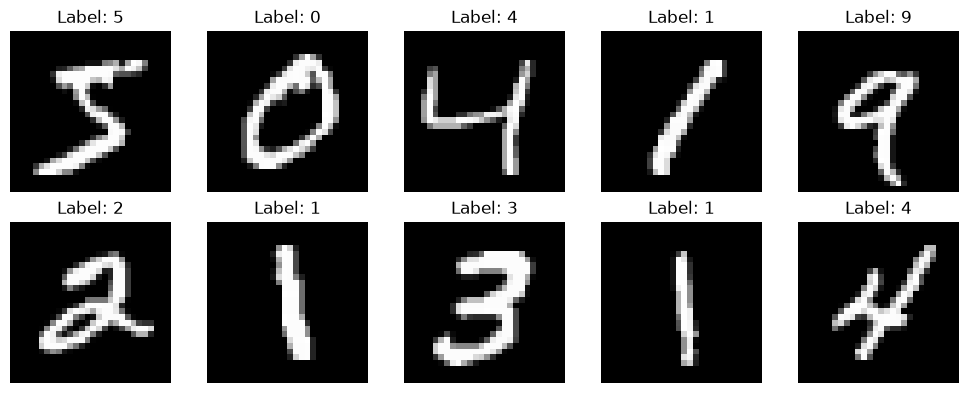

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
import numpy as np

# Flatten images
X_train_flat = X_train.reshape(60000, 784)
X_test_flat = X_test.reshape(10000, 784)

# Normalize pixel values
X_train_normalized = X_train_flat.astype("float32") / 255.0
X_test_normalized = X_test_flat.astype("float32") / 255.0

print("Training data shape:", X_train_normalized.shape)
print("Testing data shape:", X_test_normalized.shape)

print("Minimum pixel value:", X_train_normalized.min())
print("Maximum pixel value:", X_train_normalized.max())

Training data shape: (60000, 784)
Testing data shape: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader, random_split

In [24]:
X = torch.tensor(X_train_normalized, dtype=torch.float32)
y = torch.tensor(y_train, dtype=torch.long)

dataset = TensorDataset(X, y)

train_dataset, val_dataset = random_split(
    dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 54000
Validation samples: 6000


In [25]:
class MNIST_MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model = MNIST_MLP()

print(model)

MNIST_MLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [26]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [27]:
epochs = 15

train_accuracies = []
val_accuracies = []

for epoch in range(epochs):

    model.train()

    correct = 0
    total = 0

    for images, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_accuracy = 100 * correct / total
    train_accuracies.append(train_accuracy)

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_accuracy = 100 * correct / total
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Training Accuracy: {train_accuracy:.2f}% "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/15] Training Accuracy: 87.62% Validation Accuracy: 92.88%
Epoch [2/15] Training Accuracy: 94.41% Validation Accuracy: 94.22%
Epoch [3/15] Training Accuracy: 96.04% Validation Accuracy: 95.92%
Epoch [4/15] Training Accuracy: 96.87% Validation Accuracy: 96.35%
Epoch [5/15] Training Accuracy: 97.56% Validation Accuracy: 96.67%
Epoch [6/15] Training Accuracy: 98.02% Validation Accuracy: 96.93%
Epoch [7/15] Training Accuracy: 98.38% Validation Accuracy: 97.00%
Epoch [8/15] Training Accuracy: 98.71% Validation Accuracy: 96.78%
Epoch [9/15] Training Accuracy: 98.85% Validation Accuracy: 96.97%
Epoch [10/15] Training Accuracy: 99.11% Validation Accuracy: 97.43%
Epoch [11/15] Training Accuracy: 99.21% Validation Accuracy: 97.47%
Epoch [12/15] Training Accuracy: 99.39% Validation Accuracy: 96.95%
Epoch [13/15] Training Accuracy: 99.43% Validation Accuracy: 97.17%
Epoch [14/15] Training Accuracy: 99.56% Validation Accuracy: 97.52%
Epoch [15/15] Training Accuracy: 99.54% Validation Accura

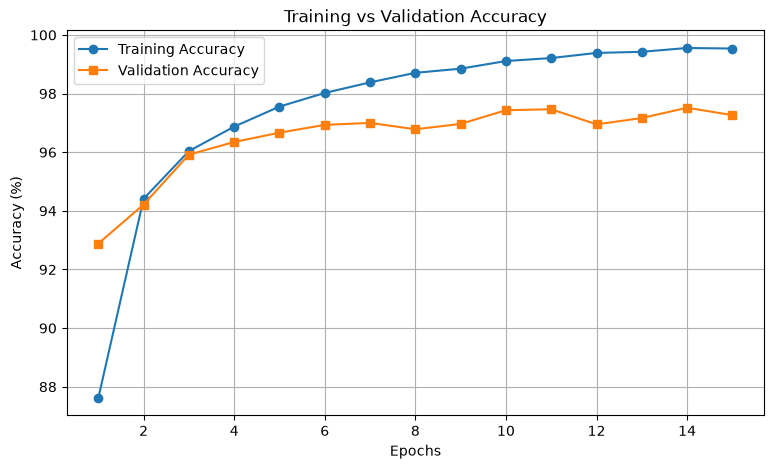

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, epochs + 1), train_accuracies,
         marker="o", label="Training Accuracy")

plt.plot(range(1, epochs + 1), val_accuracies,
         marker="s", label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()